# Use the Instrument Catalog

The `tatc.catalog` module holds instruments of past and present missions, in configurations that were compared with their data products. Rather than choosing a field of regard and attitude by hand, an analysis can take an entry's instruments with the attitude they were tested with.

Each entry also states how well it was tested. Its *tier* is computed from its results and the thresholds of the [validation standard](../validation/standard.rst):

* `validated`: every test of the standard passed, with fitted values tested on data at least 30 days from their fitting data;
* `partial`: some tests failed or are missing, and the entry lists each gap;
* `nominal`: published values only.

Every entry, including a validated one, has limitations, listed with its configurations. The [instrument catalog](../validation/catalog.rst) lists the entries and their results.

First, list the entries with their class and tier.

In [1]:
import pandas as pd
from tatc.catalog import get_entry, list_entries

pd.DataFrame(
    [
        {
            "entry": entry.id,
            "instrument": entry.name,
            "class": entry.instrument_class.value,
            "tier": entry.validation.tier.value,
            "configurations": ", ".join(entry.configurations),
            "platforms": ", ".join(p.name for p in entry.platforms),
        }
        for entry in list_entries()
    ]
)

,entry,instrument,class,tier,configurations,platforms
0,abi,ABI,geostationary,partial,"full_disk, sst_good_quality, lst_good_quality",GOES-19
1,ahi,AHI,geostationary,partial,"full_disk, cloud_top_height",Himawari-9
2,airs,AIRS,cross_track,partial,"swath, footprints",Aqua
3,amsr2,AMSR2,conical,partial,"swath, sample_size",GCOM-W
4,amsua,AMSU-A,cross_track,partial,"swath, footprints",Aqua
5,ascat,ASCAT,scatterometer,validated,swaths,Metop-C
6,atlas,ATLAS,lidar,partial,beam_pairs,ICESat-2
7,atms,ATMS,cross_track,validated,"swath, beams, swath_noaa_21, beams_noaa_21","NOAA-20, NOAA-21"
8,avhrr,AVHRR,cross_track,partial,"swath, pixels","Metop-C, Metop-B"
9,ceres,CERES,cross_track,partial,swath,NOAA-20


Entries can be filtered by class and tier. For example, the validated pushbroom imagers:

In [2]:
[entry.name for entry in list_entries("pushbroom", "validated")]

['HARP2', 'MSI', 'OLI', 'SPEXone', 'TROPOMI']

## Inspect an Entry

An entry has one or more configurations, each for a use (its *grade*): `coverage` for which points are observed, `timing` for when as well, and `sample_size` for the size of samples. The `validation` property gives the results of each configuration against the standard's gates. Here, the entry of the Visible Infrared Imaging Radiometer Suite (VIIRS):

In [3]:
viirs = get_entry("viirs")
validation = viirs.validation
print(f"{viirs.name}: {validation.tier.value}")

pd.DataFrame(
    [
        {
            "configuration": key,
            "grade": viirs.configurations[key].grade.value,
            "metric": result.gate.metric,
            "result": result.value,
            "limit": ("<= " if result.gate.at_most else ">= ")
            + f"{result.gate.limit:g} {result.gate.unit}",
            "passed": result.passed,
        }
        for key, configuration in validation.configurations.items()
        for result in configuration.gates
    ]
)

VIIRS: validated


,configuration,grade,metric,result,limit,passed
0,swath,coverage,pass_recall,99.781634,>= 99 %,True
1,swath,coverage,pass_precision,98.435374,>= 95 %,True
2,swath,coverage,swath_width_median,3.323232,<= 5 km,True
3,swath,coverage,footprint_iou_median,0.986996,>= 0.95,True
4,swath,coverage,epoch_p95,1.984222,<= 3 s,True
5,swath_noaa_21,coverage,pass_recall,99.965362,>= 99 %,True
6,swath_noaa_21,coverage,pass_precision,98.599248,>= 95 %,True
7,swath_noaa_21,coverage,swath_width_median,2.829423,<= 5 km,True
8,swath_noaa_21,coverage,footprint_iou_median,0.989783,>= 0.95,True
9,swath_noaa_21,coverage,epoch_p95,2.230665,<= 3 s,True


The limitations of a configuration state what it does not represent. Read them before relying on a result.

In [4]:
for text in viirs.limitations + viirs.configurations["swath"].limitations:
    print("-", text)

- The swath and zones configurations are fitted on NOAA-20, and swath_noaa_21 on NOAA-21. NOAA-20's configurations on NOAA-21 are a transfer that warns on use; on 2026-11-05, every pass was found, with epochs within 2.2 s (95th percentile), but the swath width differed by 21.0 km, and the zones' pixels lay 3.2 km from the samples (median), within the gate. No configuration was tested on Suomi NPP.
- The view is centered on nadir. The outermost samples measure 55.96 deg to the left and 56.13 deg to the right.
- Epochs are tested only to about 2 s, because reference times are interpolated from granule outlines, so this configuration is at the coverage grade.


## Build a Satellite

The catalog holds no orbits, as element sets age. Supply an orbit for the analysis period, here from a two-line element set of NOAA-20. `to_satellite` builds a satellite with the instruments of a configuration (the default, if none is given) and the attitude they were tested with. VIIRS's view is tailored to the analysis time step, so the time step is needed too. Naming the platform gives a warning if the configuration was not tested on it.

In [5]:
from tatc.schemas import GeneralPerturbationsOrbit

noaa20_tle = [
    "1 43013U 17073A   26224.00000000  .00000058  00000-0  27779-4 0  2098",
    "2 43013 098.7781 162.9718 0002024 099.5641 067.3984 14.19520627452396",
]
time_step = 10  # seconds

noaa20 = viirs.to_satellite(
    GeneralPerturbationsOrbit.from_tle(noaa20_tle),
    time_step=time_step,
    platform="noaa-20",
    name="NOAA-20",
)
noaa20.attitude

Attitude(type='attitude', velocity_frame=<VelocityFrame.INERTIAL: 'inertial'>, yaw_angle=0, roll_angle=0, pitch_angle=0, yaw_angle_profile=None, roll_angle_profile=None, pitch_angle_profile=None, blind_intervals=None)

VIIRS scans perpendicular to the inertial velocity, so its satellite has an attitude in the inertial velocity frame. A hand-built instrument in TAT-C's default Earth-fixed frame would misplace the swath edges along track. Similarly, build a Sentinel-2B satellite with the entry of the MultiSpectral Instrument (MSI):

In [6]:
msi = get_entry("msi")
sentinel2b_tle = [
    "1 42063U 17013A   26224.50119745  .00000132  00000+0  67047-4 0  9998",
    "2 42063  98.5671 298.4722 0001257  90.2435 269.8892 14.30821792492696",
]
sentinel2b = msi.to_satellite(
    GeneralPerturbationsOrbit.from_tle(sentinel2b_tle),
    time_step=time_step,
    platform="sentinel-2b",
    name="Sentinel-2B",
)
print(f"MSI: {msi.validation.tier.value}")
for text in msi.configurations["swath"].limitations[-1:]:
    print("-", text)

MSI: validated
- Swept swaths were added after the configuration's first holdout, on 2026-08-12, where views tailored to the time step departed from the swath at long time steps; the swath's intersection over union was at least 0.994 at 10 s and 0.992 at 30 s, but 0.949 at 120 s (Sentinel-2A and 2B), failing the standard's 0.95. Rescored with swept swaths, it was 0.995 to 0.997 at every time step, with the other results unchanged; the configuration was then tested on 2026-11-10, a day not used before, which its record holds.


MSI's entry is validated. Its instrument is swept (`is_swept`): the swath is the strip its cross-track line sweeps, so it does not depend on the time step.

## Analyze

The satellites work with TAT-C's analysis functions as any other. Collect the observations of a point over ten days:

In [7]:
from datetime import datetime, timedelta, timezone

from tatc.analysis import collect_observations
from tatc.schemas import Point

point = Point(id=0, latitude=33.45, longitude=-112.07)
start = datetime(2026, 8, 12, tzinfo=timezone.utc)
end = start + timedelta(days=10)

observations = collect_observations(point, [noaa20, sentinel2b], start, end)
observations.groupby("satellite").epoch.agg(["count", "min", "max"])

,count,min,max
satellite,,,
NOAA-20,26,2026-08-12 08:22:01.630842174+00:00,2026-08-21 20:12:42.347778102+00:00
Sentinel-2B,3,2026-08-14 18:24:53.392749203+00:00,2026-08-21 18:14:54.725855722+00:00


Compute the swaths of both satellites over two orbits, swept between the times of the steps. VIIRS's swath, about 3,000 km wide, covers both poles on each orbit, so on this map the swaths of its two orbits join at high latitudes, leaving gaps (white) between the ascending and descending halves. MSI's swath is about 295 km wide.

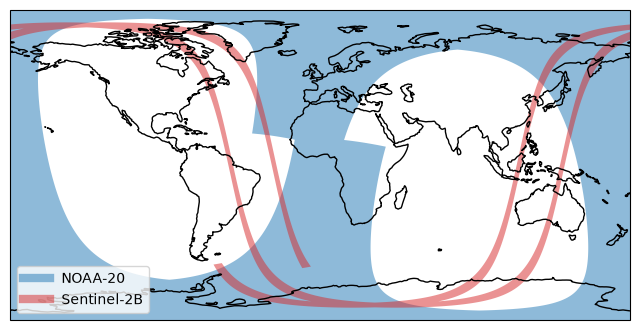

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from tatc.analysis import compute_ground_track

times = [start + timedelta(seconds=s) for s in range(0, 2 * 101 * 60, time_step)]

fig, ax = plt.subplots(figsize=(8, 5), subplot_kw={"projection": ccrs.PlateCarree()})
for satellite, color in [(noaa20, "tab:blue"), (sentinel2b, "tab:red")]:
    track = compute_ground_track(satellite, times)
    track.plot(ax=ax, color=color, alpha=0.5, transform=ccrs.PlateCarree())
    ax.plot([], [], color=color, linewidth=6, alpha=0.5, label=satellite.name)
ax.coastlines()
ax.set_global()
ax.legend(loc="lower left")
plt.show()

## Untested Platforms

A configuration's results hold for the platforms it was tested on. Using it for another platform, here the default configuration of VIIRS on NOAA-21, gives a warning. Where angles differ between sister platforms, an entry has a configuration fitted on each, as VIIRS's `swath_noaa_21`; results of a configuration on a sister platform it was not fitted on are recorded as transfers, which do not count toward its tier.

In [9]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    viirs.build(
        orbit=GeneralPerturbationsOrbit.from_tle(noaa20_tle),
        time_step=time_step,
        platform="noaa-21",
    )
for warning in caught:
    print(warning.message)

configuration 'swath' of 'viirs' was tested on ['noaa-20'], not on 'noaa-21'


## Multiple Instruments

Some configurations have several instruments. The configuration's `grouping` states how to analyze them: `union` instruments together form the swath, so analyze them with `instrument_index=None`, while `alternatives` are different views, analyzed one at a time. `build` returns the instruments with the attitude and the index to use, without building a satellite:

In [10]:
tropomi = get_entry("tropomi")
payload = tropomi.build(
    orbit=GeneralPerturbationsOrbit.from_tle(noaa20_tle), time_step=time_step
)
print(f"{len(payload.instruments)} instruments, grouping: {payload.grouping}")

10 instruments, grouping: union


Here the orbit only sets the tailored along-track field of view; for an analysis of TROPOMI, use an orbit of Sentinel-5P.